# Glucose Prediction — Model Training

### Objective

Predict a patient's glucose level approximately **30 minutes into the future** using historical glucose measurements, glucose trends, meal information, insulin/bolus data, basal insulin, exercise, sleep, finger-stick measurements, and time-based features.

### Dataset

`data/processed/ml_dataset.csv`

### Models

1. Naive Baseline
2. Linear Regression
3. Random Forest Regressor

### Evaluation Metrics

- MAE
- RMSE
- R²

### Important

The dataset is time-series and patient-specific, therefore the train/test split must preserve **patient-wise chronological order** to avoid temporal leakage.

In [2]:
pip install joblib

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
DATA_PATH = "../data/processed/ml_dataset.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (65499, 21)


,Patient,timestamp,glucose_value,glucose_lag_1,glucose_lag_2,glucose_lag_3,glucose_lag_6,glucose_change_5min,glucose_change_15min,meal_carbs,...,basal_value,temp_basal_value,exercise_duration,exercise_intensity,sleep_duration_hours,sleep_quality,finger_stick_value,hour,day_of_week,target_glucose_30min
0,540-ws-training,2027-05-19 11:36:29,76,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.95,0.0,0.0,0.0,0.0,0.0,80.0,11,2,71.0
1,540-ws-training,2027-05-19 11:41:29,72,76.0,0.0,0.0,0.0,-4.0,0.0,0.0,...,0.95,0.0,0.0,0.0,0.0,0.0,80.0,11,2,78.0
2,540-ws-training,2027-05-19 11:46:29,68,72.0,76.0,0.0,0.0,-4.0,0.0,0.0,...,0.95,0.0,0.0,0.0,0.0,0.0,80.0,11,2,90.0
3,540-ws-training,2027-05-19 11:51:29,65,68.0,72.0,76.0,0.0,-3.0,-11.0,0.0,...,0.95,0.0,0.0,0.0,0.0,0.0,80.0,11,2,99.0
4,540-ws-training,2027-05-19 11:56:29,63,65.0,68.0,72.0,0.0,-2.0,-9.0,0.0,...,0.95,0.0,0.0,0.0,0.0,0.0,80.0,11,2,110.0


In [29]:
print("Columns:")
for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Columns:
1. Patient
2. timestamp
3. glucose_value
4. glucose_lag_1
5. glucose_lag_2
6. glucose_lag_3
7. glucose_lag_6
8. glucose_change_5min
9. glucose_change_15min
10. meal_carbs
11. bolus_dose
12. basal_value
13. temp_basal_value
14. exercise_duration
15. exercise_intensity
16. sleep_duration_hours
17. sleep_quality
18. finger_stick_value
19. hour
20. day_of_week
21. target_glucose_30min


In [30]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

df = df.sort_values(
    ["Patient", "timestamp"]
).reset_index(drop=True)

print("Timestamp conversion and sorting completed.")

print("\nFirst timestamp:")
print(df["timestamp"].min())

print("\nLast timestamp:")
print(df["timestamp"].max())

Timestamp conversion and sorting completed.

First timestamp:
2025-04-16 11:17:05

Last timestamp:
2027-07-03 23:26:44


In [31]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate Patient + Timestamp records:")
print(
    df.duplicated(
        subset=["Patient", "timestamp"]
    ).sum()
)

print("\nNumber of patients:")
print(df["Patient"].nunique())

print("\nPatients:")
print(df["Patient"].unique())

Dataset shape: (65499, 21)

Missing values:
0

Duplicate Patient + Timestamp records:
0

Number of patients:
6

Patients:
<StringArray>
['540-ws-training', '544-ws-training', '552-ws-training', '567-ws-training',
 '584-ws-training', '596-ws-training']
Length: 6, dtype: str


In [32]:
FEATURE_COLUMNS = [
    "glucose_value",
    "glucose_lag_1",
    "glucose_lag_2",
    "glucose_lag_3",
    "glucose_lag_6",
    "glucose_change_5min",
    "glucose_change_15min",
    "meal_carbs",
    "bolus_dose",
    "basal_value",
    "temp_basal_value",
    "exercise_duration",
    "exercise_intensity",
    "sleep_duration_hours",
    "sleep_quality",
    "finger_stick_value",
    "hour",
    "day_of_week"
]

TARGET_COLUMN = "target_glucose_30min"

X = df[FEATURE_COLUMNS]
y = df[TARGET_COLUMN]

print("Number of features:", len(FEATURE_COLUMNS))
print("X shape:", X.shape)
print("y shape:", y.shape)

Number of features: 18
X shape: (65499, 18)
y shape: (65499,)


In [33]:
print("Feature data types:\n")
print(X.dtypes)

print("\nTarget data type:")
print(y.dtype)

Feature data types:

glucose_value             int64
glucose_lag_1           float64
glucose_lag_2           float64
glucose_lag_3           float64
glucose_lag_6           float64
glucose_change_5min     float64
glucose_change_15min    float64
meal_carbs              float64
bolus_dose              float64
basal_value             float64
temp_basal_value        float64
exercise_duration       float64
exercise_intensity      float64
sleep_duration_hours    float64
sleep_quality           float64
finger_stick_value      float64
hour                      int64
day_of_week               int64
dtype: object

Target data type:
float64


In [34]:
train_parts = []
test_parts = []

for patient in df["Patient"].unique():

    patient_df = df[df["Patient"] == patient].sort_values("timestamp")

    split_index = int(len(patient_df) * 0.80)

    train_patient = patient_df.iloc[:split_index]
    test_patient = patient_df.iloc[split_index:]

    train_parts.append(train_patient)
    test_parts.append(test_patient)

train_df = pd.concat(train_parts).sort_values(
    ["Patient", "timestamp"]
).reset_index(drop=True)

test_df = pd.concat(test_parts).sort_values(
    ["Patient", "timestamp"]
).reset_index(drop=True)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Training shape: (52396, 21)
Testing shape: (13103, 21)


In [35]:
print("Patient-wise split verification\n")

for patient in df["Patient"].unique():

    train_patient = train_df[
        train_df["Patient"] == patient
    ]

    test_patient = test_df[
        test_df["Patient"] == patient
    ]

    train_max = train_patient["timestamp"].max()
    test_min = test_patient["timestamp"].min()

    print(f"Patient: {patient}")
    print(f"  Train end: {train_max}")
    print(f"  Test start: {test_min}")
    print(f"  Valid chronological split: {train_max < test_min}")
    print()

Patient-wise split verification

Patient: 540-ws-training
  Train end: 2027-06-23 22:14:15
  Test start: 2027-06-23 22:19:15
  Valid chronological split: True

Patient: 544-ws-training
  Train end: 2027-06-16 01:19:00
  Test start: 2027-06-16 01:24:00
  Valid chronological split: True

Patient: 552-ws-training
  Train end: 2025-05-17 07:01:54
  Test start: 2025-05-17 07:06:54
  Valid chronological split: True

Patient: 567-ws-training
  Train end: 2027-02-03 03:39:02
  Test start: 2027-02-03 03:44:02
  Valid chronological split: True

Patient: 584-ws-training
  Train end: 2025-06-19 04:32:00
  Test start: 2025-06-19 04:37:00
  Valid chronological split: True

Patient: 596-ws-training
  Train end: 2027-05-16 04:47:00
  Test start: 2027-05-16 04:52:00
  Valid chronological split: True



In [36]:
X_train = train_df[FEATURE_COLUMNS]
y_train = train_df[TARGET_COLUMN]

X_test = test_df[FEATURE_COLUMNS]
y_test = test_df[TARGET_COLUMN]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (52396, 18)
y_train: (52396,)
X_test: (13103, 18)
y_test: (13103,)


In [37]:
def evaluate_model(name, y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    r2 = r2_score(y_true, y_pred)

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    }

In [38]:
naive_predictions = X_test["glucose_value"].values

naive_result = evaluate_model(
    "Naive Baseline",
    y_test,
    naive_predictions
)

print(naive_result)

{'Model': 'Naive Baseline', 'MAE': 19.62252919178814, 'RMSE': np.float64(29.052657942547587), 'R²': 0.7767284570016397}


In [39]:
linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

linear_predictions = linear_model.predict(X_test)

linear_result = evaluate_model(
    "Linear Regression",
    y_test,
    linear_predictions
)

print(linear_result)

{'Model': 'Linear Regression', 'MAE': 17.4484668234855, 'RMSE': np.float64(26.574540858701926), 'R²': 0.8131929890453394}


In [40]:
linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

linear_predictions = linear_model.predict(X_test)

linear_result = evaluate_model(
    "Linear Regression",
    y_test,
    linear_predictions
)

print(linear_result)

{'Model': 'Linear Regression', 'MAE': 17.4484668234855, 'RMSE': np.float64(26.574540858701926), 'R²': 0.8131929890453394}


In [41]:
random_forest_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest...")

random_forest_model.fit(
    X_train,
    y_train
)

print("Random Forest training completed.")

rf_predictions = random_forest_model.predict(X_test)

rf_result = evaluate_model(
    "Random Forest",
    y_test,
    rf_predictions
)

print(rf_result)

Training Random Forest...
Random Forest training completed.
{'Model': 'Random Forest', 'MAE': 17.574544203095023, 'RMSE': np.float64(26.406743452303207), 'R²': 0.8155446210250856}


In [42]:
print("Model Comparison:")
print(results)

print("\nBest model based on R²:")

best_model = results.loc[
    results["R²"].idxmax()
]

print(best_model)

Model Comparison:
               Model        MAE       RMSE        R²
0  Linear Regression  17.448467  26.574541  0.813193
1      Random Forest  17.574544  26.406743  0.815545
2     Naive Baseline  19.622529  29.052658  0.776728

Best model based on R²:
Model    Random Forest
MAE          17.574544
RMSE         26.406743
R²            0.815545
Name: 1, dtype: object


In [43]:
best_model_name = results.iloc[0]["Model"]

print("Best model:", best_model_name)

print("\nPerformance:")
print(results.iloc[0])

Best model: Linear Regression

Performance:
Model    Linear Regression
MAE              17.448467
RMSE             26.574541
R²                0.813193
Name: 0, dtype: object


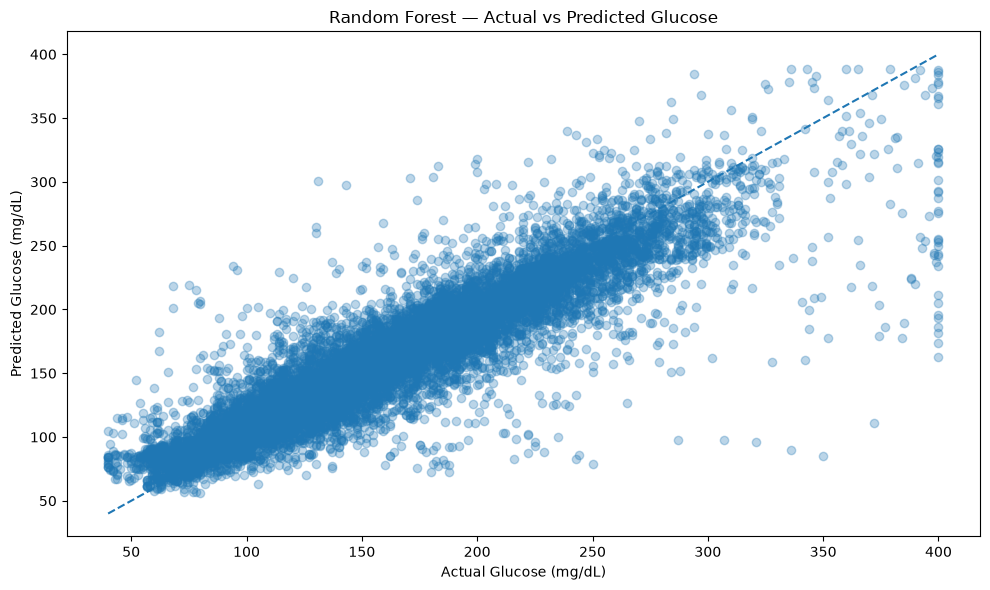

In [44]:
plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.3
)

plt.xlabel("Actual Glucose (mg/dL)")
plt.ylabel("Predicted Glucose (mg/dL)")
plt.title("Random Forest — Actual vs Predicted Glucose")

min_value = min(y_test.min(), rf_predictions.min())
max_value = max(y_test.max(), rf_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.tight_layout()
plt.show()

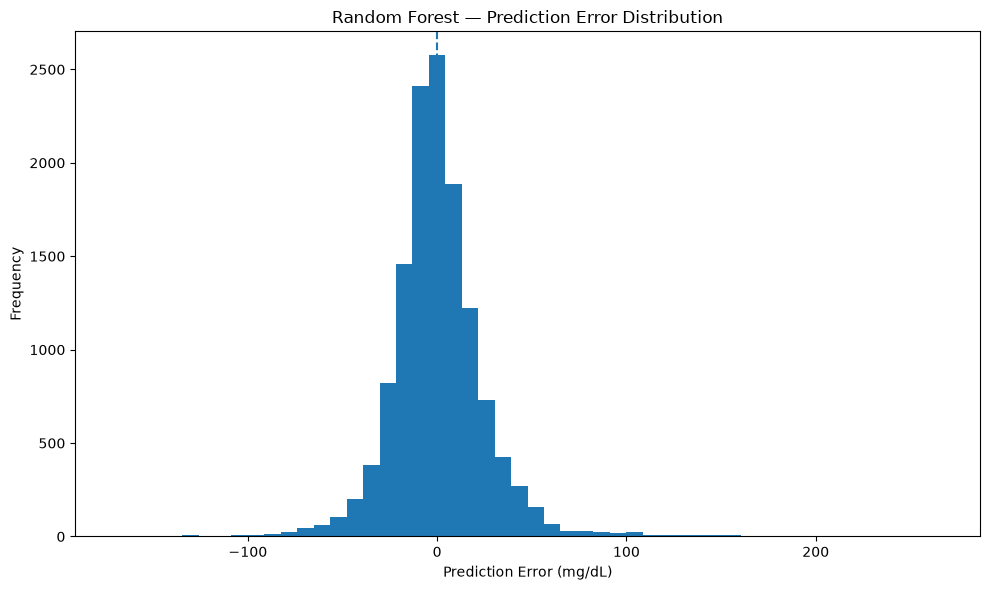

In [45]:
errors = y_test.values - rf_predictions

plt.figure(figsize=(10, 6))

plt.hist(
    errors,
    bins=50
)

plt.xlabel("Prediction Error (mg/dL)")
plt.ylabel("Frequency")
plt.title("Random Forest — Prediction Error Distribution")

plt.axvline(
    0,
    linestyle="--"
)

plt.tight_layout()
plt.show()

In [46]:
MODEL_PATH = os.path.join(
    MODEL_DIR,
    "random_forest_glucose_model.pkl"
)

In [47]:
MODEL_DIR = "../models"

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

MODEL_PATH = os.path.join(
    MODEL_DIR,
    "random_forest_glucose_model.pkl"
)

FEATURE_PATH = os.path.join(
    MODEL_DIR,
    "feature_columns.pkl"
)

joblib.dump(
    random_forest_model,
    MODEL_PATH
)

joblib.dump(
    FEATURE_COLUMNS,
    FEATURE_PATH
)

print("Model saved to:")
print(MODEL_PATH)

print("\nFeature list saved to:")
print(FEATURE_PATH)

Model saved to:
../models/random_forest_glucose_model.pkl

Feature list saved to:
../models/feature_columns.pkl


In [48]:
loaded_model = joblib.load(
    MODEL_PATH
)

loaded_features = joblib.load(
    FEATURE_PATH
)

test_predictions = loaded_model.predict(
    X_test[loaded_features]
)

loaded_mae = mean_absolute_error(
    y_test,
    test_predictions
)

loaded_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        test_predictions
    )
)

loaded_r2 = r2_score(
    y_test,
    test_predictions
)

print("Reloaded model evaluation:")
print(f"MAE  : {loaded_mae:.4f}")
print(f"RMSE : {loaded_rmse:.4f}")
print(f"R²   : {loaded_r2:.4f}")

Reloaded model evaluation:
MAE  : 17.5745
RMSE : 26.4067
R²   : 0.8155


# Model Training Summary

The final ML dataset contained:

- 65,499 samples
- 18 predictive features
- 1 prediction target
- 0 missing feature values

The models evaluated were:

1. Naive Baseline
2. Linear Regression
3. Random Forest Regressor

The dataset was split using a **patient-wise chronological train/test split** to reduce temporal leakage.

The Random Forest model was evaluated using:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R² Score

The best-performing model was saved to:

`models/random_forest_glucose_model.pkl`

The corresponding feature list was saved to:

`models/feature_columns.pkl`

The trained model will be used in the subsequent evaluation and prediction pipeline.